# IS 362 – Preprocessing Data for scikit-learn

**Nathan Fernandez**

## Introduction

The purpose of this assignment is to prepare a dataset for predictive analysis using Python and pandas. Data preprocessing involves transforming raw data into a format that can be used more effectively for statistical analysis and machine learning.

This assignment uses the Mushroom dataset from the UCI Machine Learning Repository. The dataset contains information about different mushroom characteristics, including whether a mushroom is classified as edible or poisonous.

The analysis will focus on three attributes: mushroom classification (edible or poisonous), odor, and one additional characteristic selected from the dataset. These attributes will be organized into a pandas DataFrame with meaningful column names. The original categorical codes will then be converted into numeric values to prepare the data for future analysis using scikit-learn.

Exploratory data analysis will be performed to examine the distribution of each selected attribute and visualize the relationships between mushroom classification and the other characteristics using scatterplots.

The goal is to identify whether odor and the additional selected characteristic may be useful predictors of mushroom classification. This preprocessing work will also provide a foundation for the predictive analysis required in Project 4.

In [1]:
import pandas as pd

# Load the original UCI Mushroom dataset directly from GitHub
file_path = "https://raw.githubusercontent.com/njf328/IS-362/refs/heads/main/agaricus-lepiota.data"

# Read the dataset (the original file has no column headers)
mushrooms = pd.read_csv(file_path, header=None)

# Display the first five rows
mushrooms.head()

,0,1,2,3,4,5,6,7,8,9,...,13,14,15,16,17,18,19,20,21,22
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [2]:
# Select the three attributes for analysis
mushroom_df = mushrooms[[0, 5, 20]].copy()

# Assign meaningful column names
mushroom_df.columns = ["classification", "odor", "spore_print_color"]

# Display the first five rows
mushroom_df.head()

,classification,odor,spore_print_color
0,p,p,k
1,e,a,n
2,e,l,n
3,p,p,k
4,e,n,n


In [3]:
# Convert mushroom classification into numeric values
classification_map = {"e": 0, "p": 1}

# Convert odor categories into numeric values
odor_map = {
    "a": 0, "l": 1, "c": 2,
    "y": 3, "f": 4, "m": 5,
    "n": 6, "p": 7, "s": 8
}

# Convert spore-print colors into numeric values
spore_color_map = {
    "k": 0, "n": 1, "b": 2,
    "h": 3, "r": 4, "o": 5,
    "u": 6, "w": 7, "y": 8
}

# Apply the mappings to the selected columns
mushroom_numeric = mushroom_df.copy()

mushroom_numeric["classification"] = mushroom_numeric["classification"].map(classification_map)
mushroom_numeric["odor"] = mushroom_numeric["odor"].map(odor_map)
mushroom_numeric["spore_print_color"] = mushroom_numeric["spore_print_color"].map(spore_color_map)

# Display the first five rows
mushroom_numeric.head()

,classification,odor,spore_print_color
0,1,7,0
1,0,0,1
2,0,1,1
3,1,7,0
4,0,6,1


In [4]:
# Check the size of the numeric dataset
print ("Dataset shape:", mushroom_numeric.shape)

# Check the data types of each column
print ("\nColumn data types:")
print (mushroom_numeric.dtypes)

# Check for missing values
print ("\nMissing values:")
print (mushroom_numeric.isnull().sum())

Dataset shape: (8124, 3)

Column data types:
classification       int64
odor                 int64
spore_print_color    int64
dtype: object

Missing values:
classification       0
odor                 0
spore_print_color    0
dtype: int64


## Data Selection and Preprocessing

The original UCI Mushroom dataset contains 8,124 observations and 23 columns, including the mushroom classification and 22 descriptive attributes.

For this assignment, three columns were selected: classification (column 0), odor (column 5), and spore-print color (column 20). Classification identifies whether a mushroom is edible or poisonous, while odor and spore-print color are characteristics that may help predict its classification.

The selected columns were assigned meaningful names to make the DataFrame easier to understand.

Because the original dataset represents categorical values using letters, these values were converted into numeric codes. Edible mushrooms were assigned a classification of 0, and poisonous mushrooms were assigned a classification of 1. The odor and spore-print-color categories were also assigned numeric values.

These numeric codes represent categories rather than quantities or rankings. The resulting dataset was checked to confirm that all 8,124 observations were retained and that no missing values were introduced during conversion.

Mushroom Classification Distribution:
classification
0    4208
1    3916
Name: count, dtype: int64


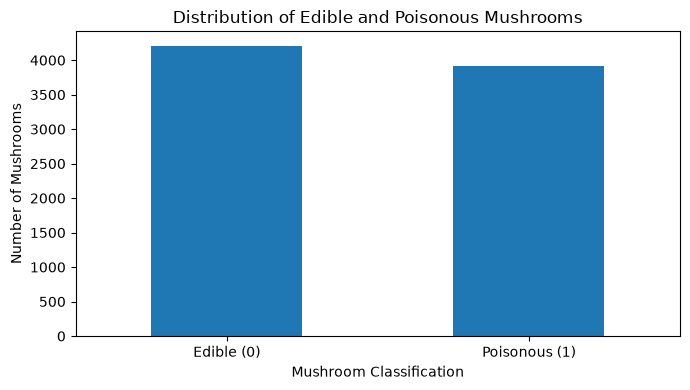

In [5]:
import matplotlib.pyplot as plt

# Count the number of edible and poisonous mushrooms
classification_counts = mushroom_numeric["classification"].value_counts().sort_index()

# Display the counts
print ("Mushroom Classification Distribution:")
print (classification_counts)

# Create a bar chart
classification_counts.plot(kind="bar", figsize=(7, 4))

plt.title("Distribution of Edible and Poisonous Mushrooms")
plt.xlabel("Mushroom Classification")
plt.ylabel("Number of Mushrooms")
plt.xticks([0, 1], ["Edible (0)", "Poisonous (1)"], rotation=0)
plt.tight_layout()
plt.show()

Mushroom Odor Distribution:
odor
0     400
1     400
2     192
3     576
4    2160
5      36
6    3528
7     256
8     576
Name: count, dtype: int64


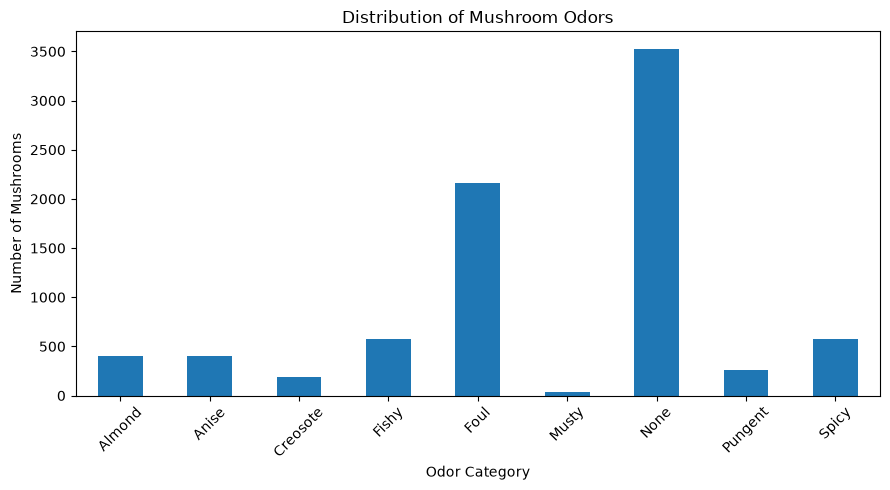

In [6]:
# Count the mushrooms in each odor category
odor_counts = mushroom_numeric["odor"].value_counts().sort_index()

# Display the counts
print ("Mushroom Odor Distribution:")
print (odor_counts)

# Create a bar chart of odor categories
odor_counts.plot(kind="bar", figsize=(9, 5))

plt.title("Distribution of Mushroom Odors")
plt.xlabel("Odor Category")
plt.ylabel("Number of Mushrooms")

# Replace numeric labels with meaningful odor names
plt.xticks(
    range(9),
    ["Almond", "Anise", "Creosote", "Fishy", "Foul",
     "Musty", "None", "Pungent", "Spicy"],
    rotation=45
)

plt.tight_layout()
plt.show()

Mushroom Spore-Print Color Distribution:
spore_print_color
0    1872
1    1968
2      48
3    1632
4      72
5      48
6      48
7    2388
8      48
Name: count, dtype: int64


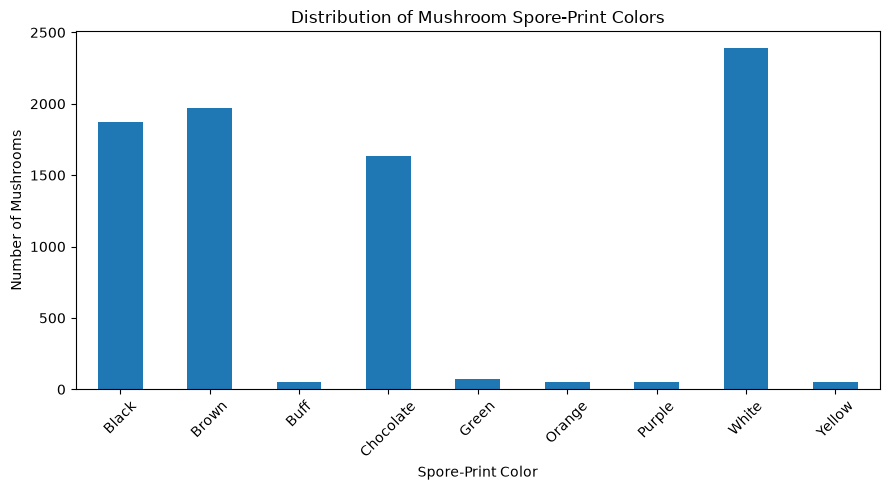

In [7]:
# Count the mushrooms in each spore-print-color category
spore_counts = mushroom_numeric["spore_print_color"].value_counts().sort_index()

# Display the counts
print ("Mushroom Spore-Print Color Distribution:")
print (spore_counts)

# Create a bar chart of spore-print colors
spore_counts.plot(kind="bar", figsize=(9, 5))

plt.title("Distribution of Mushroom Spore-Print Colors")
plt.xlabel("Spore-Print Color")
plt.ylabel("Number of Mushrooms")

# Replace numeric labels with meaningful color names
plt.xticks(
    range(9),
    ["Black", "Brown", "Buff", "Chocolate", "Green",
     "Orange", "Purple", "White", "Yellow"],
    rotation=45
)

plt.tight_layout()
plt.show()

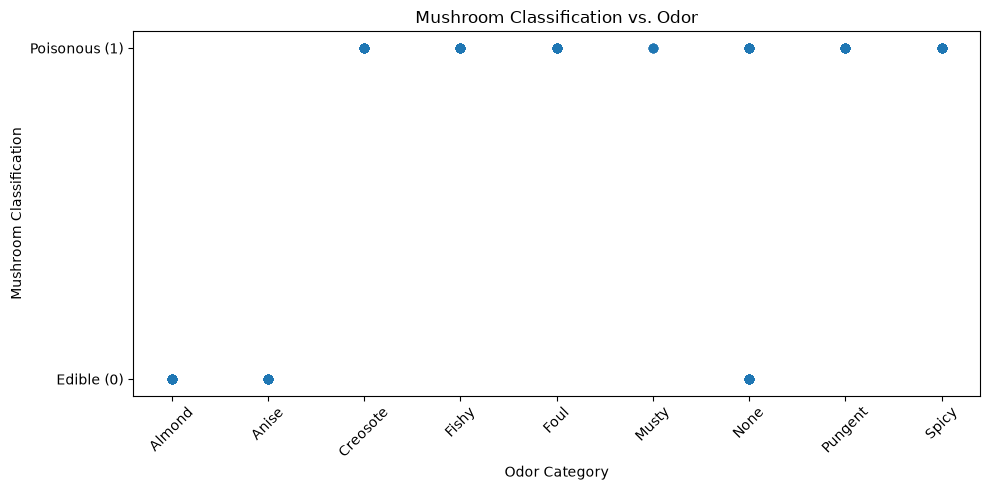

In [8]:
# Create a scatterplot comparing odor and mushroom classification
plt.figure(figsize=(10, 5))

plt.scatter(
    mushroom_numeric["odor"],
    mushroom_numeric["classification"],
    alpha=0.1
)

plt.title("Mushroom Classification vs. Odor")
plt.xlabel("Odor Category")
plt.ylabel("Mushroom Classification")

plt.xticks(
    range(9),
    ["Almond", "Anise", "Creosote", "Fishy", "Foul",
     "Musty", "None", "Pungent", "Spicy"],
    rotation=45
)

plt.yticks([0, 1], ["Edible (0)", "Poisonous (1)"])

plt.tight_layout()
plt.show()

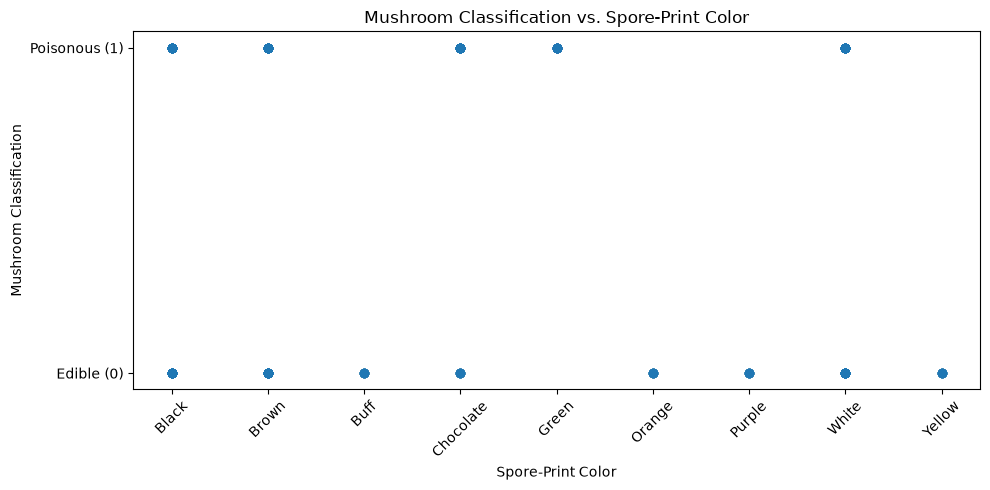

In [9]:
# Create a scatterplot comparing spore-print color and mushroom classification
plt.figure(figsize=(10, 5))

plt.scatter(
    mushroom_numeric["spore_print_color"],
    mushroom_numeric["classification"],
    alpha=0.1
)

plt.title("Mushroom Classification vs. Spore-Print Color")
plt.xlabel("Spore-Print Color")
plt.ylabel("Mushroom Classification")

plt.xticks(
    range(9),
    ["Black", "Brown", "Buff", "Chocolate", "Green",
     "Orange", "Purple", "White", "Yellow"],
    rotation=45
)

plt.yticks([0, 1], ["Edible (0)", "Poisonous (1)"])

plt.tight_layout()
plt.show()

## Preliminary Conclusions

The exploratory data analysis provides some useful insights into the relationships between mushroom characteristics and their classification as edible or poisonous.

**Mushroom Classification:** The dataset contains 8,124 mushrooms, including 4,208 edible mushrooms and 3,916 poisonous mushrooms. The distribution is relatively balanced, with slightly more edible mushrooms than poisonous mushrooms.

**Odor:** The scatterplot suggests that odor may be a strong predictor of mushroom classification. Mushrooms with almond or anise odors appear exclusively in the edible category, while mushrooms with creosote, fishy, foul, musty, pungent, or spicy odors appear exclusively in the poisonous category. Mushrooms with no odor appear in both categories, indicating that odor alone may not always be sufficient to determine classification.

**Spore-Print Color:** Spore-print color also appears to provide useful information. Green spore prints appear exclusively among poisonous mushrooms, while buff, orange, purple, and yellow spore prints appear exclusively among edible mushrooms. However, black, brown, chocolate, and white spore prints occur in both categories, making this characteristic less reliable on its own.

**Overall Findings:** Based on these preliminary observations, odor appears to be a stronger predictor of mushroom classification than spore-print color. Both characteristics may be useful for predictive analysis, particularly when considered together. However, because these variables are categorical and many observations overlap in the scatterplots, further analysis is needed to evaluate their predictive performance.

The numeric dataset prepared in this assignment provides a foundation for the classification analysis that will be performed in Project 4 using scikit-learn.

*Note: These findings describe patterns in the UCI Mushroom dataset and should not be used to determine whether wild mushrooms are safe to eat.*